# Unemployment in India: Regional and Temporal Trends, and the Impact of COVID-19

**Objective:** Explore unemployment data across Indian states (May 2019 to June 2020) to find regional and monthly patterns, and measure how the COVID-19 lockdown changed unemployment.

**Tech stack:** Python, pandas, matplotlib, seaborn

**Dataset:** `Unemployment_in_India.csv` (monthly state-level estimates, split into Rural and Urban areas)


### Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#### 📚 Libraries and Functions Used

| Library / Function | Purpose |
|---|---|
| **pandas** | Data manipulation and analysis |
| **numpy** | Numerical operations and calculations |
| **matplotlib** | Data visualization |
| **seaborn** | Statistical data visualization |

### Load `Unemployment_in_India.csv` **Dataset**

In [2]:
file_path = '/content/drive/MyDrive/OASIS INFOBYTE Internship/Task2/Unemployment in India.csv'
# Load the dataset file
df = pd.read_csv(file_path)
df.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


# Inspecting the data

In [4]:
print("Shape:", df.shape)

Shape: (768, 7)


In [5]:
print(list(df.columns))   # Print columns names

['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']


In [6]:
df.info()     # Check basic information about the data like (data types, non-null, counts,......)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    object 
 1    Date                                     740 non-null    object 
 2    Frequency                                740 non-null    object 
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 42.1+ KB


In [7]:
print(df.isnull().sum())   # Number of missing values

Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemployment Rate (%)            28
 Estimated Employed                         28
 Estimated Labour Participation Rate (%)    28
Area                                        28
dtype: int64


In [10]:
df.tail(28)

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
740,West Bengal,31-05-2019,Monthly,7.25,11306177.0,46.37,Urban
741,West Bengal,30-06-2019,Monthly,7.38,10611498.0,43.51,Urban
742,West Bengal,31-07-2019,Monthly,7.91,10779829.0,44.38,Urban
743,West Bengal,31-08-2019,Monthly,7.27,11456493.0,46.77,Urban
744,West Bengal,30-09-2019,Monthly,7.79,11158649.0,45.74,Urban
745,West Bengal,31-10-2019,Monthly,7.83,10563686.0,43.25,Urban
746,West Bengal,30-11-2019,Monthly,6.61,10768462.0,43.44,Urban
747,West Bengal,31-12-2019,Monthly,7.24,11335696.0,45.97,Urban
748,West Bengal,31-01-2020,Monthly,7.27,11208617.0,45.39,Urban
749,West Bengal,29-02-2020,Monthly,7.55,10871168.0,44.09,Urban


In [11]:
# Rows that have at least one missing value
null_rows = df[df.isnull().any(axis=1)]
print("Rows with nulls:", len(null_rows))
null_rows

Rows with nulls: 28


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
359,NaN,NaN,NaN,NaN,NaN,NaN,NaN
360,NaN,NaN,NaN,NaN,NaN,NaN,NaN
361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
362,NaN,NaN,NaN,NaN,NaN,NaN,NaN
363,NaN,NaN,NaN,NaN,NaN,NaN,NaN
364,NaN,NaN,NaN,NaN,NaN,NaN,NaN
365,NaN,NaN,NaN,NaN,NaN,NaN,NaN
366,NaN,NaN,NaN,NaN,NaN,NaN,NaN
367,NaN,NaN,NaN,NaN,NaN,NaN,NaN
368,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
df.describe() # Get summary statistics (mean, std, min, max, quartiles)

,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740.000000,7.400000e+02,740.000000
mean,11.787946,7.204460e+06,42.630122
std,10.721298,8.087988e+06,8.111094
min,0.000000,4.942000e+04,13.330000
25%,4.657500,1.190404e+06,38.062500
50%,8.350000,4.744178e+06,41.160000
75%,15.887500,1.127549e+07,45.505000
max,76.740000,4.577751e+07,72.570000


#### **Summary: Inspecting the Data**

- **Size:** the raw file has **768 rows and 7 columns**: Region, Date, Frequency, Estimated Unemployment Rate (%), Estimated Employed, Estimated Labour Participation Rate (%) and Area.
- **Data types:** `Date` is stored as text, so it must be converted to datetime before any time-based analysis.
- **Column names:** several names and text values have stray leading spaces (for example `" Date"` and `" Frequency"`), which would cause errors when selecting columns, so they need to be stripped.
- **Missing values:** each column has **28 null values**, and they sit in the same rows. This means 28 rows are completely empty, not partly filled.


**Next step:** clean the data by stripping spaces, dropping the 28 empty rows, renaming the columns and converting `Date` to datetime.

#  Data Cleaning

In this section I fix the problems found during inspection: extra spaces, empty rows, long column names and the `Date` column stored as text.

##### Removing Spaces

In [14]:
# Remove leading/trailing spaces from column names
df.columns = df.columns.str.strip()

# Remove spaces from the text columns
for col in ["Region", "Date", "Frequency", "Area"]:
    df[col] = df[col].str.strip()

print(list(df.columns))

['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area']


##### Drop impty rows

In [15]:
# Drop rows where every column is empty
df = df.dropna(how="all").reset_index(drop=True)

print("Shape after dropping empty rows:", df.shape)
print("Nulls left:", df.isnull().sum().sum())

Shape after dropping empty rows: (740, 7)
Nulls left: 0


##### Rename columns

In [16]:
# Shorter column names that are easier to type
df = df.rename(columns={
    "Estimated Unemployment Rate (%)": "Unemployment_Rate",
    "Estimated Employed": "Employed",
    "Estimated Labour Participation Rate (%)": "Labour_Participation_Rate",
})

df.head()

,Region,Date,Frequency,Unemployment_Rate,Employed,Labour_Participation_Rate,Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


##### Type conversation

In [17]:
# Date is text in dd-mm-yyyy format, so parse it with an explicit format
df["Date"] = pd.to_datetime(df["Date"], format="%d-%m-%Y")

print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())
print("Duplicate rows:", df.duplicated().sum())
print("Regions:", df["Region"].nunique())
df.dtypes

Date range: 2019-05-31 to 2020-06-30
Duplicate rows: 0
Regions: 28


,0
Region,object
Date,datetime64[ns]
Frequency,object
Unemployment_Rate,float64
Employed,float64
Labour_Participation_Rate,float64
Area,object


##### **Observations**
- After cleaning, the data has **740 rows and no missing values**.
- It covers **28 regions** from **May 2019 to June 2020** (14 months).
- There are no duplicate rows.

# Exploratory Data Analysis (EDA)

##### Region-wise average unemployment rate

In [18]:
# Average of each indicator per region, sorted from highest unemployment
region_avg = (df.groupby("Region")[["Unemployment_Rate", "Employed", "Labour_Participation_Rate"]]
                .mean().round(2)
                .sort_values("Unemployment_Rate", ascending=False))
region_avg

,Unemployment_Rate,Employed,Labour_Participation_Rate
Region,,,
Tripura,28.35,717002.64,61.82
Haryana,26.28,3557072.46,42.74
Jharkhand,20.58,4469240.43,41.67
Bihar,18.92,12366189.14,38.15
Himachal Pradesh,18.54,1059823.71,44.22
Delhi,16.50,2627512.86,38.93
Jammu & Kashmir,16.19,1799931.67,41.03
Chandigarh,15.99,316831.25,39.34
Rajasthan,14.06,10041064.75,39.97


###### **Observations**
- Tripura (about 28%) and Haryana (about 26%) have the highest averages, while Meghalaya (about 4.8%) and Odisha (about 5.7%) have the lowest.
- The gap between states is very large, and it covers the whole period, not only the lockdown.

##### Month-wise trend

Date
2019-05-31     8.87
2019-06-30     9.30
2019-07-31     9.03
2019-08-31     9.64
2019-09-30     9.05
2019-10-31     9.90
2019-11-30     9.87
2019-12-31     9.50
2020-01-31     9.95
2020-02-29     9.96
2020-03-31    10.70
2020-04-30    23.64
2020-05-31    24.88
2020-06-30    11.90
Name: Unemployment_Rate, dtype: float64


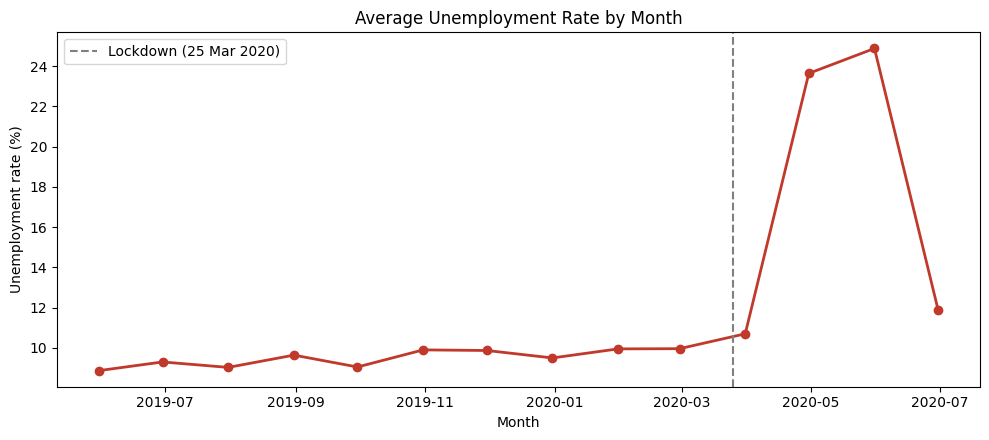

In [19]:
# Average unemployment rate per month across all regions
monthly = df.groupby("Date")["Unemployment_Rate"].mean().round(2)
print(monthly)

plt.figure(figsize=(10, 4.5))
plt.plot(monthly.index, monthly.values, marker="o", color="#c0392b", linewidth=2)
plt.axvline(pd.Timestamp("2020-03-25"), color="grey", linestyle="--", label="Lockdown (25 Mar 2020)")
plt.title("Average Unemployment Rate by Month")
plt.xlabel("Month")
plt.ylabel("Unemployment rate (%)")
plt.legend()
plt.tight_layout()
plt.show()

###### **Observations**
- Before the lockdown the average stayed around 9% to 10%.
- It jumped to 23.6% in April 2020 and 24.9% in May, more than double the earlier level.
- It fell to 11.9% in June, a fast but incomplete recovery.

### Time-Series Analysis

##### Unemployment in major states
I compare Delhi, Maharashtra, Tamil Nadu and Bihar.

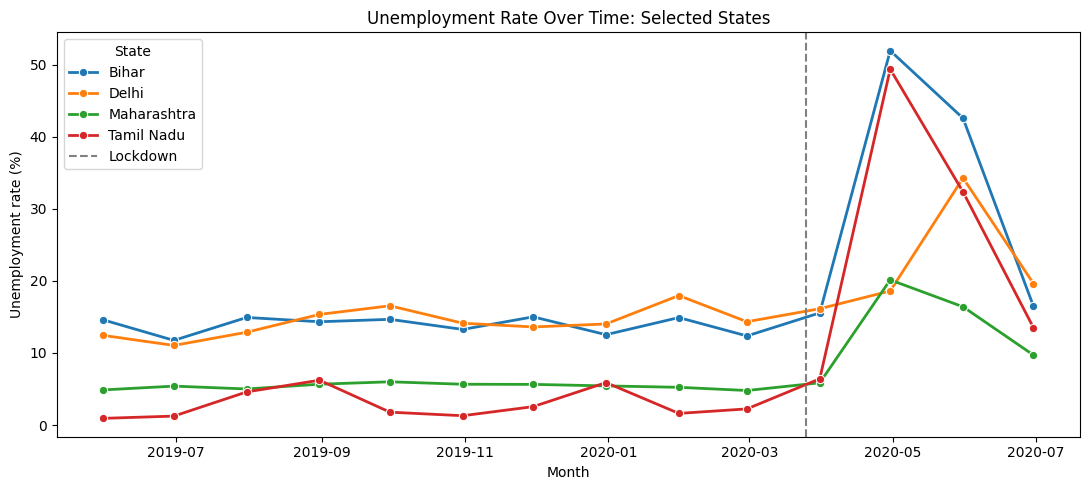

In [20]:
states = ["Delhi", "Maharashtra", "Tamil Nadu", "Bihar"]

state_ts = (df[df["Region"].isin(states)]
              .groupby(["Date", "Region"])["Unemployment_Rate"].mean()
              .reset_index())

plt.figure(figsize=(11, 5))
sns.lineplot(data=state_ts, x="Date", y="Unemployment_Rate", hue="Region", marker="o", linewidth=2)
plt.axvline(pd.Timestamp("2020-03-25"), color="grey", linestyle="--", label="Lockdown")
plt.title("Unemployment Rate Over Time: Selected States")
plt.xlabel("Month")
plt.ylabel("Unemployment rate (%)")
plt.legend(title="State")
plt.tight_layout()
plt.show()

###### **Observations**
- Tamil Nadu rose from about 2.2% in February 2020 to 49.4% in April, the sharpest jump.
- Bihar peaked at about 51.9% in April from an already high base (about 12%).
- Maharashtra peaked at about 20% in April, while Delhi peaked later, at about 34% in May, so timing differs by state.
- All four recovered a lot by June, but most stayed above their pre-lockdown level.

### Bar chart of the top 10 states
###### Top 10 States by Average Unemployment Rate

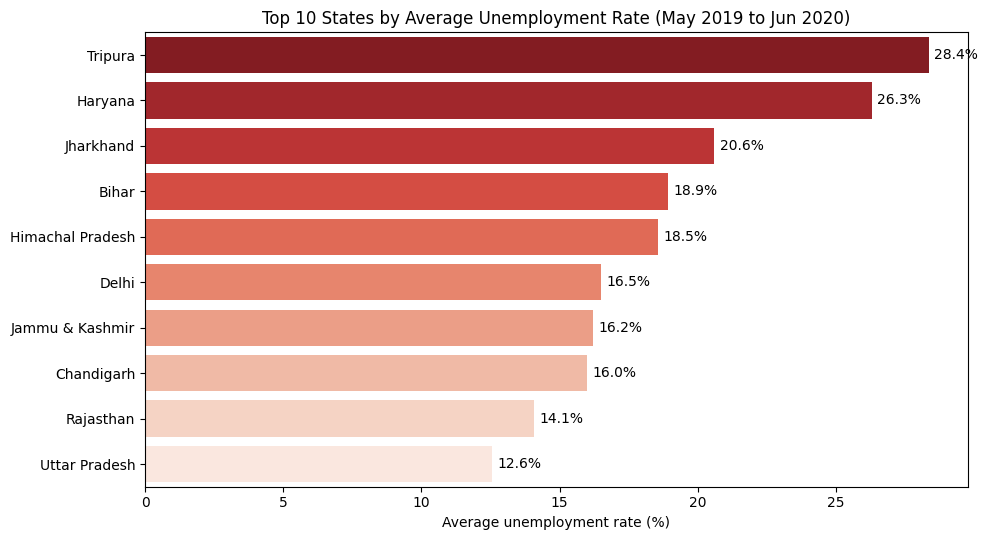

In [21]:
top10 = (df.groupby("Region")["Unemployment_Rate"].mean()
           .sort_values(ascending=False).head(10).reset_index())

plt.figure(figsize=(10, 5.5))
ax = sns.barplot(data=top10, x="Unemployment_Rate", y="Region",
                 hue="Region", palette="Reds_r", legend=False)
for i, v in enumerate(top10["Unemployment_Rate"]):
    ax.text(v + 0.2, i, f"{v:.1f}%", va="center")   # value label on each bar
plt.title("Top 10 States by Average Unemployment Rate (May 2019 to Jun 2020)")
plt.xlabel("Average unemployment rate (%)")
plt.ylabel("")
plt.tight_layout()
plt.show()

######**Observations**
- Tripura (28.4%) and Haryana (26.3%) lead by a clear margin, followed by Jharkhand (20.6%) and Bihar (18.9%).

### Correlation Analysis

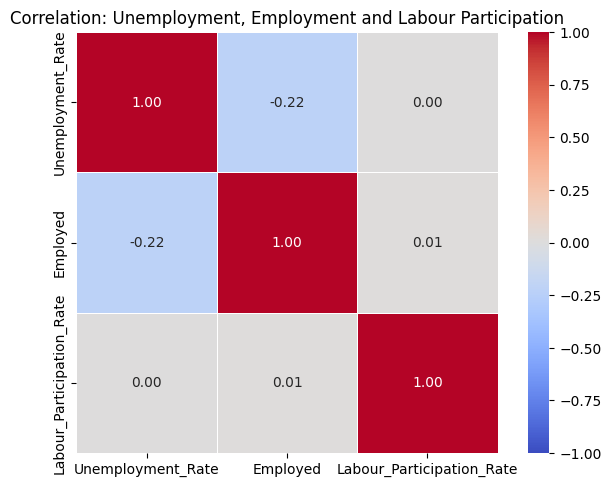

In [22]:
corr = df[["Unemployment_Rate", "Employed", "Labour_Participation_Rate"]].corr()

plt.figure(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title("Correlation: Unemployment, Employment and Labour Participation")
plt.tight_layout()
plt.show()

###### **Observations**
- Unemployment rate and number employed have a weak negative correlation (about -0.22): more unemployment goes with fewer people employed, but the link is weak.
- Labour participation is almost uncorrelated with the other two (about 0.00 and 0.01).



### Pre-COVID vs Post-COVID

The national lockdown began on 25 March 2020. Rows are dated at month end, so March 2020 falls in the post-COVID group.

##### Overall comparison

            Unemployment_Rate    Employed  Labour_Participation_Rate
Period                                                              
Pre-COVID                9.51  7466027.87                      43.89
Post-COVID              17.77  6517203.34                      39.33


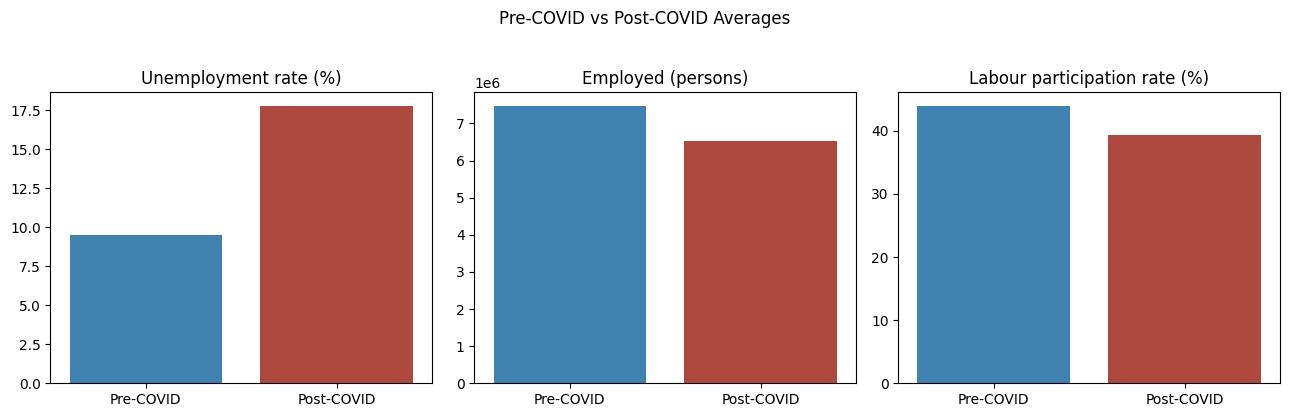

In [23]:
cutoff = pd.Timestamp("2020-03-25")
df["Period"] = np.where(df["Date"] < cutoff, "Pre-COVID", "Post-COVID")

period_mean = (df.groupby("Period")[["Unemployment_Rate", "Employed", "Labour_Participation_Rate"]]
                 .mean().round(2).loc[["Pre-COVID", "Post-COVID"]])
print(period_mean)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
titles = ["Unemployment rate (%)", "Employed (persons)", "Labour participation rate (%)"]
for ax, col, t in zip(axes, period_mean.columns, titles):
    sns.barplot(x=period_mean.index, y=period_mean[col], hue=period_mean.index,
                palette=["#2e86c1", "#c0392b"], legend=False, ax=ax)
    ax.set_title(t)
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.suptitle("Pre-COVID vs Post-COVID Averages", y=1.03)
plt.tight_layout()
plt.show()

###### **Observations**
- The average unemployment rate rose from about 9.5% to about 17.8%, an increase of roughly 8 points.
- The average number employed fell from about 7.47 million to 6.52 million (around 13% lower).
- Labour participation fell from about 43.9% to 39.3%, so fewer people were even looking for work.

##### State-wise change

In [24]:
state_change = (df.pivot_table(index="Region", columns="Period",
                               values="Unemployment_Rate", aggfunc="mean")
                  [["Pre-COVID", "Post-COVID"]])
state_change["Change"] = state_change["Post-COVID"] - state_change["Pre-COVID"]
state_change = state_change.sort_values("Change", ascending=False).round(2)
display(state_change.head(8))
display(state_change.tail(3))

Period,Pre-COVID,Post-COVID,Change
Region,,,
Puducherry,1.59,38.96,37.36
Tamil Nadu,2.84,25.40,22.57
Jharkhand,14.28,36.35,22.07
Bihar,13.83,31.63,17.80
Karnataka,3.23,15.28,12.05
Haryana,22.94,34.65,11.72
Kerala,6.99,17.95,10.96
Telangana,4.66,15.44,10.79


Period,Pre-COVID,Post-COVID,Change
Region,,,
Himachal Pradesh,19.13,17.07,-2.06
Tripura,29.01,26.70,-2.31
Jammu & Kashmir,17.22,12.89,-4.33


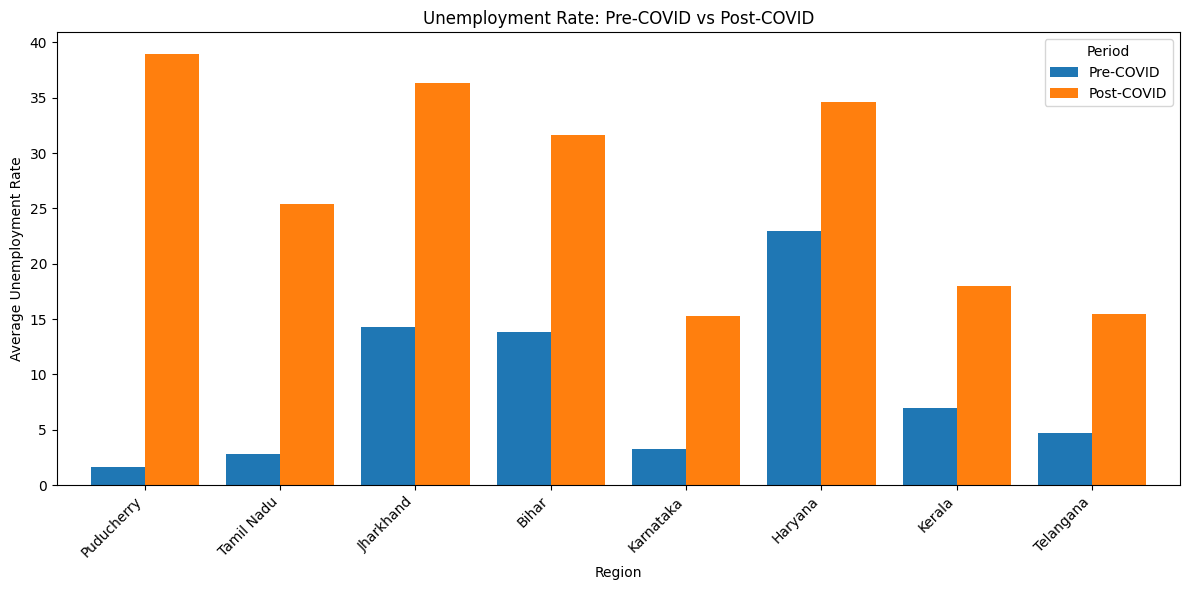

In [25]:
comparison = state_change[["Pre-COVID", "Post-COVID"]].head(8) #head(8) selects the top eight regions by Change

comparison.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Unemployment Rate: Pre-COVID vs Post-COVID")
plt.xlabel("Region")
plt.ylabel("Average Unemployment Rate")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Period")
plt.tight_layout()
plt.show()


######**Observations**
- The biggest increases were in Puducherry (about +37 points), Tamil Nadu (+23), Jharkhand (+22) and Bihar (+18).
- Jammu & Kashmir, Tripura and Himachal Pradesh were slightly lower after March, largely because their pre-COVID levels were already high.